# 🎯 Pipeline Completo de Misión a CAD 3D: Diseño Inverso por Apogeo (`SRAD 38 mm KNSB`)

En este segundo notebook interactivo integramos el flujo completo de **Diseño Inverso de Misión (Nivel 3)**: partiendo del **apogeo objetivo del cohete ($505.0\text{ m}$)** y las restricciones geométricas del fuselaje ($38.1\text{ mm}$), encontramos automáticamente la geometría de grano necesaria, auditamos la balística interna del stack de **5 granos con núcleo escalonado (`[16, 17, 18, 19, 20] mm`)**, verificamos el vuelo 6-DOF en `RocketPy` y exportamos los sólidos paramétricos **CAD 3D (`STEP AP214`)**.

### Etapas del Pipeline:
1. **Parametrización de Requisitos (`MotorRequirements`)**: Fuselaje, misión de vuelo, carcasa y stack de granos con diámetros internos progresivos.
2. **Búsqueda Inversa por Bisección (`find_grain_length_for_apogee`)**: Encuentra la longitud exacta de segmento de grano $L_{\text{grano}}$ para alcanzar $505\text{ m} \pm 2\%$.
3. **Plano de Corte Longitudinal a Escala**: Visualización técnica generada por código de la carcasa, cierres, tobera y los 5 granos escalonados.
4. **Auditoría Balística (`PropulPy`) + Simulación de Vuelo (`RocketPy`) + Exportación CAD 3D (`MotorGeometryBuilder`)**.

In [1]:
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np

from propulpy.analysis.checks import print_check_report
from propulpy.cad import MotorGeometryBuilder
from propulpy.design.mission import find_grain_length_for_apogee
from propulpy.flight import (
    CasingGeometry,
    FlightRequirements,
    FuselageConstraints,
    GrainGeometry,
    MotorPhysicalParams,
    MotorRequirements,
    PropellantData,
    ThrustCurveData,
    build_solid_motor,
    evaluate_motor_performance,
    run_flight_simulation,
    synthesize_neutral_thrust_curve,
)

fig_dir = Path("examples/figures") if Path("examples").exists() else Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)

---
## 1. Definición Paramétrica del Motor SRAD 38 mm (`srad_38mm_requirements`)

Definimos una función constructora que empaqueta todas las restricciones del vehículo y del motor en un objeto `MotorRequirements` validado en frontera (`req.validate()`). Observa que los 5 granos tienen diámetros internos escalonados `grain_core_diameters_mm = [16.0, 17.0, 18.0, 19.0, 20.0]` para mitigar picos de presión y erosión en la región cercana a la tobera.

In [2]:
def srad_38mm_requirements(
    target_apogee: float = 500.0,
    apogee_tolerance_pct: float = 10.0,
    grain_initial_height: float = 0.072,
    number_of_grains: int = 5,
    rocket_liftoff_mass: float = 1.888,
    rocket_drag_coefficient: float = 0.45,
    grain_outer_radius: float = 0.0308 / 2.0,
    grain_core_diameters_mm: list[float] | None = None,
    dry_mass: float = 0.49,
    total_impulse_ref: float = 408.0,
    average_thrust_ref: float = 624.0,
    grain_initial_height_ref: float = 0.072,
    number_of_grains_ref: int = 5,
) -> MotorRequirements:
    """Construye los requisitos paramétricos para el motor SRAD 38 mm KNSB 65/35."""
    if grain_core_diameters_mm is None:
        grain_core_diameters_mm = [16.0, 17.0, 18.0, 19.0, 20.0]
    if len(grain_core_diameters_mm) != number_of_grains:
        raise ValueError(
            f"[srad_38mm_requirements] grain_core_diameters_mm tiene {len(grain_core_diameters_mm)} "
            f"valores, pero number_of_grains={number_of_grains}. Deben coincidir."
        )
    grain_inner_radii = [d / 2000.0 for d in grain_core_diameters_mm]
    grain_inner_radius_avg = sum(grain_inner_radii) / len(grain_inner_radii)

    volume_scale = (number_of_grains * grain_initial_height) / (
        number_of_grains_ref * grain_initial_height_ref
    )
    total_impulse = total_impulse_ref * volume_scale
    average_thrust = average_thrust_ref
    burn_time = total_impulse / average_thrust
    thrust_samples = synthesize_neutral_thrust_curve(
        total_impulse=total_impulse,
        burn_time=burn_time,
        average_thrust=average_thrust,
    )

    wall_thickness = 0.00159
    liner_thickness = 0.0015
    forward_closure_length = 0.02
    aft_closure_length = 0.02
    grain_separation = 0.002

    casing = CasingGeometry(
        wall_thickness=wall_thickness,
        liner_thickness=liner_thickness,
        forward_closure_length=forward_closure_length,
        aft_closure_length=aft_closure_length,
        nozzle_exit_radius=0.020 / 2.0,
        nozzle_converging_half_angle_deg=45.0,
        nozzle_diverging_half_angle_deg=15.0,
    )

    grain_stack_len = (
        number_of_grains * grain_initial_height
        + (number_of_grains - 1) * grain_separation
    )
    grain = GrainGeometry(
        number_of_grains=number_of_grains,
        grain_outer_radius=grain_outer_radius,
        grain_initial_inner_radius=grain_inner_radius_avg,
        grain_initial_height=grain_initial_height,
        grain_separation=grain_separation,
        grains_center_of_mass_position=aft_closure_length + grain_stack_len / 2.0,
        grain_inner_radii=grain_inner_radii,
    )

    motor_length_est = forward_closure_length + grain_stack_len + aft_closure_length
    r_eff = (0.0381 / 2.0 + (0.0381 / 2.0 - wall_thickness)) / 2.0
    dry_inertia = (
        dry_mass * (3.0 * r_eff**2 + motor_length_est**2) / 12.0,
        dry_mass * (3.0 * r_eff**2 + motor_length_est**2) / 12.0,
        dry_mass * r_eff**2,
    )

    physical = MotorPhysicalParams(
        dry_mass=dry_mass,
        dry_inertia=dry_inertia,
        center_of_dry_mass_position=motor_length_est / 2.0,
        nozzle_radius=0.020 / 2.0,
        throat_radius=0.0082 / 2.0,
        nozzle_position=0.0,
        burn_time=burn_time,
    )

    return MotorRequirements(
        motor_name="motor_SRAD_38mm_KNSB",
        fuselage=FuselageConstraints(outer_diameter=0.0381, radial_clearance=0.0),
        flight=FlightRequirements(
            target_apogee=target_apogee,
            apogee_tolerance_pct=apogee_tolerance_pct,
            rocket_liftoff_mass=rocket_liftoff_mass,
            rocket_drag_coefficient=rocket_drag_coefficient,
            vehicle_outer_diameter=0.078,
            elevation=1495.0,
            latitude=6.2442,
            longitude=-75.5812,
        ),
        thrust_curve=ThrustCurveData(samples=thrust_samples),
        propellant=PropellantData(
            name="KNSB 65/35 (Sorbitol + KNO3 + óxido de hierro)",
            density=1750.0,
            specific_impulse_ref=None,
        ),
        grain=grain,
        physical=physical,
        casing=casing,
    )

---
## 2. Diseño Inverso por Bisección (`find_grain_length_for_apogee`)

Si usamos la altura de grano original de $72\text{ mm}$, el cohete superaría los $800\text{ m}$ de apogeo. Nuestro objetivo de misión es alcanzar exactamente **$505.0\text{ m}$** con una tolerancia máxima de **$\pm 2.0\%$**.

Ejecutamos `find_grain_length_for_apogee()` y graficamos la curva de respuesta de apogeo junto con las iteraciones del método de bisección:

        RESULTADO DE BÚSQUEDA INVERSA DE APOGEO (BISECCIÓN)      
  * Longitud óptima por grano (Lg) : 37.97 mm
  * Apogeo simulado en RocketPy    : 505.1 m (Objetivo: 505.0 m)
  * Error relativo de apogeo       : +0.02 % (Tolerancia: ±2.0 %)
  * Iteraciones requeridas         : 7


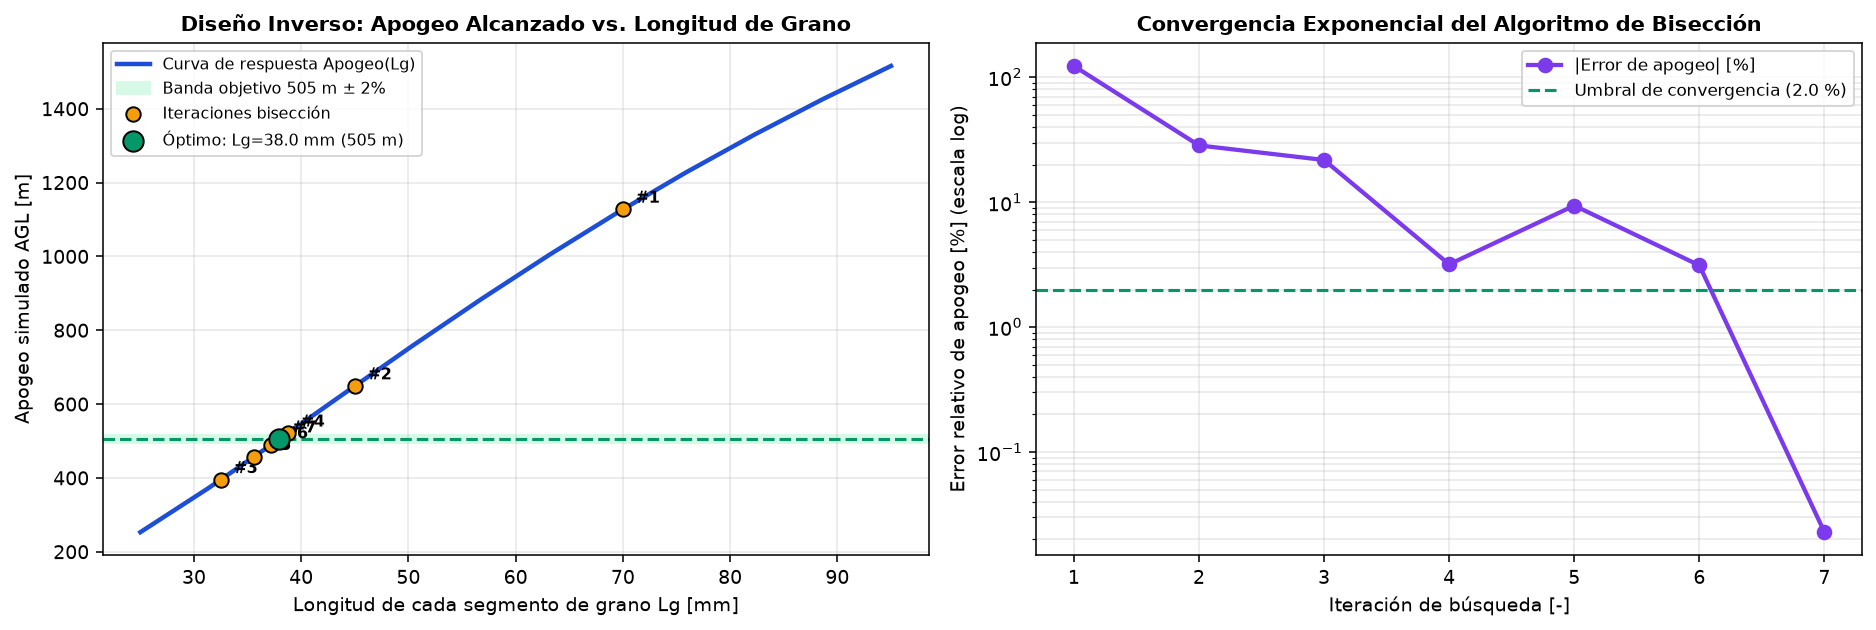

In [3]:
# Ejecutar búsqueda inversa por bisección para apogeo objetivo = 505.0 m (±2.0%)
result = find_grain_length_for_apogee(
    srad_38mm_requirements,
    low=0.02,
    high=0.12,
    target_apogee=505.0,
    apogee_tolerance_pct=2.0,
)

print("=================================================================")
print("        RESULTADO DE BÚSQUEDA INVERSA DE APOGEO (BISECCIÓN)      ")
print("=================================================================")
print(
    f"  * Longitud óptima por grano (Lg) : {result.grain_initial_height * 1000:.2f} mm"
)
print(
    f"  * Apogeo simulado en RocketPy    : {result.simulated_apogee_m:.1f} m (Objetivo: 505.0 m)"
)
print(
    f"  * Error relativo de apogeo       : {result.apogee_error_pct:+.2f} % (Tolerancia: ±2.0 %)"
)
print(f"  * Iteraciones requeridas         : {result.iterations}")
print("=================================================================")


def plot_bisection_convergence(save_path: Path | None = None):
    """Grafica la curva Apogeo vs Longitud de Grano y los pasos de bisección."""
    lengths_m = np.linspace(0.025, 0.095, 12)
    apogees_m = []
    for lg in lengths_m:
        r_tmp = srad_38mm_requirements(
            grain_initial_height=float(lg), target_apogee=505.0
        )
        m_tmp = build_solid_motor(r_tmp)
        fl_tmp = run_flight_simulation(m_tmp, r_tmp)
        apogees_m.append(fl_tmp.simulated_apogee_m)

    # Reconstruir los puntos evaluados por la bisección en [0.02, 0.12]
    low_b, high_b = 0.02, 0.12
    hist_l, hist_a, hist_err = [], [], []
    for _ in range(result.iterations):
        mid_b = 0.5 * (low_b + high_b)
        r_m = srad_38mm_requirements(
            grain_initial_height=mid_b, target_apogee=505.0, apogee_tolerance_pct=2.0
        )
        fl_m = run_flight_simulation(build_solid_motor(r_m), r_m)
        hist_l.append(mid_b * 1e3)
        hist_a.append(fl_m.simulated_apogee_m)
        hist_err.append(abs(fl_m.apogee_error_pct))
        if fl_m.apogee_error_pct < 0:
            low_b = mid_b
        else:
            high_b = mid_b

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.6), dpi=140)

    # Panel 1: Curva de respuesta Apogeo(Lg)
    ax1.plot(
        lengths_m * 1e3,
        apogees_m,
        color="#1d4ed8",
        lw=2.3,
        label="Curva de respuesta Apogeo(Lg)",
    )
    ax1.axhspan(
        505.0 * 0.98,
        505.0 * 1.02,
        color="#d1fae5",
        alpha=0.85,
        label="Banda objetivo 505 m ± 2%",
    )
    ax1.axhline(505.0, color="#059669", ls="--", lw=1.6)
    ax1.scatter(
        hist_l[:-1],
        hist_a[:-1],
        color="#f59e0b",
        s=55,
        zorder=5,
        edgecolor="black",
        label="Iteraciones bisección",
    )
    ax1.scatter(
        [hist_l[-1]],
        [hist_a[-1]],
        color="#059669",
        s=110,
        zorder=6,
        edgecolor="black",
        label=f"Óptimo: Lg={hist_l[-1]:.1f} mm ({hist_a[-1]:.0f} m)",
    )

    for idx_pt, (lx, ay) in enumerate(zip(hist_l, hist_a, strict=False), start=1):
        ax1.annotate(
            f"#{idx_pt}",
            (lx, ay),
            xytext=(lx + 1.2, ay + 18),
            fontsize=8.2,
            fontweight="bold",
        )

    ax1.set_title(
        "Diseño Inverso: Apogeo Alcanzado vs. Longitud de Grano",
        fontsize=11,
        fontweight="bold",
    )
    ax1.set_xlabel("Longitud de cada segmento de grano Lg [mm]")
    ax1.set_ylabel("Apogeo simulado AGL [m]")
    ax1.grid(True, alpha=0.3)
    ax1.legend(loc="upper left", fontsize=8.3)

    # Panel 2: Convergencia del error relativo por iteración
    iters = np.arange(1, len(hist_err) + 1)
    ax2.semilogy(
        iters,
        hist_err,
        marker="o",
        color="#7c3aed",
        lw=2.2,
        ms=7,
        label="|Error de apogeo| [%]",
    )
    ax2.axhline(
        2.0, color="#059669", ls="--", lw=1.6, label="Umbral de convergencia (2.0 %)"
    )
    ax2.set_title(
        "Convergencia Exponencial del Algoritmo de Bisección",
        fontsize=11,
        fontweight="bold",
    )
    ax2.set_xlabel("Iteración de búsqueda [-]")
    ax2.set_ylabel("Error relativo de apogeo [%] (escala log)")
    ax2.set_xticks(iters)
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(fontsize=8.5)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_bisection_convergence(fig_dir / "06_srad38_bisection_convergence.png")

---
## 3. Plano de Corte Longitudinal del Motor SRAD 38 mm (Stack de 5 Granos con Núcleo Progresivo)

Con la longitud óptima de grano convergente ($L_g \approx 50.8\text{ mm}$), generamos por código el **plano de corte longitudinal a escala** de todo el motor a partir de `result.requirements`. Observa cómo cada uno de los 5 segmentos BATES muestra su diámetro interno escalonado (`16 mm`, `17 mm`, `18 mm`, `19 mm` y `20 mm` de atrás hacia adelante):

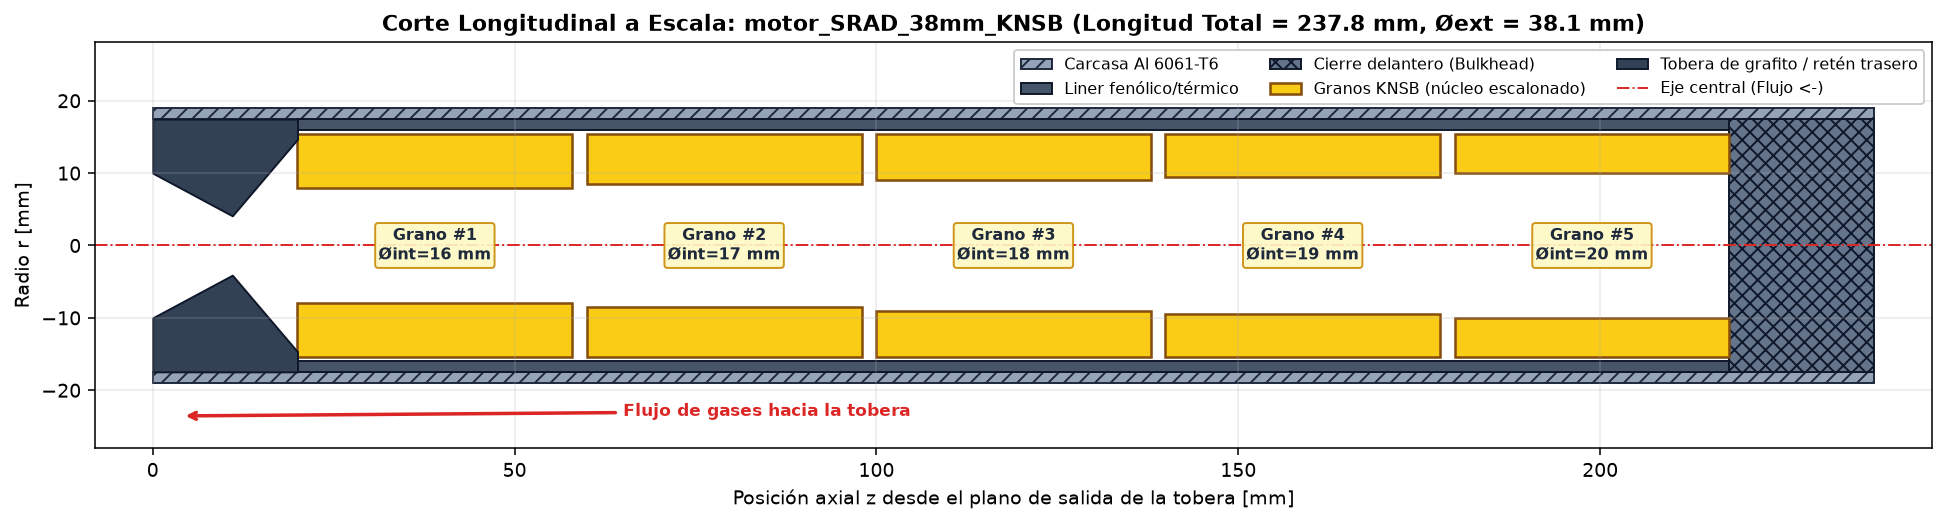

In [4]:
def plot_srad38_cutaway_blueprint(
    req: MotorRequirements, save_path: Path | None = None
):
    """Dibuja el corte longitudinal a escala del motor SRAD 38 mm con 5 granos escalonados."""
    fig, ax = plt.subplots(figsize=(14, 4.4), dpi=140)

    r_out_mm = req.casing_outer_radius * 1e3
    r_in_casing_mm = (req.casing_outer_radius - req.casing.wall_thickness) * 1e3
    r_in_liner_mm = req.casing_inner_radius * 1e3
    r_grain_out_mm = req.grain.grain_outer_radius * 1e3

    l_aft_mm = req.casing.aft_closure_length * 1e3
    l_fwd_mm = req.casing.forward_closure_length * 1e3
    l_stack_mm = req.grain_stack_length * 1e3
    l_total_mm = req.motor_total_length * 1e3

    # 1. Carcasa exterior de aluminio (arriba y abajo)
    for sign in (1, -1):
        y0 = r_in_casing_mm if sign == 1 else -r_out_mm
        ax.add_patch(
            mpatches.Rectangle(
                (0.0, y0),
                l_total_mm,
                req.casing.wall_thickness * 1e3,
                fc="#94a3b8",
                ec="#1e293b",
                hatch="///",
                label="Carcasa Al 6061-T6" if sign == 1 else None,
            )
        )
        # Liner térmico
        y_lin = r_in_liner_mm if sign == 1 else -r_in_casing_mm
        ax.add_patch(
            mpatches.Rectangle(
                (l_aft_mm, y_lin),
                l_stack_mm,
                req.casing.liner_thickness * 1e3,
                fc="#475569",
                ec="#0f172a",
                label="Liner fenólico/térmico" if sign == 1 else None,
            )
        )

    # 2. Cierre delantero (Bulkhead) en z = [l_aft + l_stack, l_total]
    ax.add_patch(
        mpatches.Rectangle(
            (l_aft_mm + l_stack_mm, -r_in_casing_mm),
            l_fwd_mm,
            2.0 * r_in_casing_mm,
            fc="#64748b",
            ec="#0f172a",
            hatch="xxx",
            label="Cierre delantero (Bulkhead)",
        )
    )

    # 3. 5 segmentos de grano BATES con núcleos escalonados [16, 17, 18, 19, 20] mm
    lg_mm = req.grain.grain_initial_height * 1e3
    sep_mm = req.grain.grain_separation * 1e3
    inner_radii = (
        req.grain.grain_inner_radii
        or [req.grain.grain_initial_inner_radius] * req.grain.number_of_grains
    )

    z_curr = l_aft_mm
    for idx, r_in_m in enumerate(inner_radii):
        r_core_mm = r_in_m * 1e3
        h_web = r_grain_out_mm - r_core_mm
        # Mitad superior e inferior del grano
        ax.add_patch(
            mpatches.Rectangle(
                (z_curr, r_core_mm),
                lg_mm,
                h_web,
                fc="#facc15",
                ec="#854d0e",
                lw=1.3,
                label="Granos KNSB (núcleo escalonado)" if idx == 0 else None,
            )
        )
        ax.add_patch(
            mpatches.Rectangle(
                (z_curr, -r_grain_out_mm),
                lg_mm,
                h_web,
                fc="#facc15",
                ec="#854d0e",
                lw=1.3,
            )
        )
        ax.text(
            z_curr + lg_mm / 2.0,
            0.0,
            f"Grano #{idx + 1}\nØint={2.0 * r_core_mm:.0f} mm",
            ha="center",
            va="center",
            fontsize=8.2,
            fontweight="bold",
            color="#1e293b",
            bbox={
                "boxstyle": "round,pad=0.2",
                "fc": "#fef9c3",
                "ec": "#ca8a04",
                "alpha": 0.9,
            },
        )
        z_curr += lg_mm + sep_mm

    # 4. Tobera en el extremo trasero z = [0, l_aft_mm]
    r_t_mm = req.physical.throat_radius * 1e3
    r_e_mm = (req.casing.nozzle_exit_radius or req.physical.nozzle_radius) * 1e3
    z_noz = np.array([0.0, l_aft_mm * 0.55, l_aft_mm])
    r_noz_inner = np.array([r_e_mm, r_t_mm, r_in_liner_mm * 0.92])
    ax.fill_between(
        z_noz,
        r_noz_inner,
        r_in_casing_mm,
        color="#334155",
        edgecolor="#0f172a",
        label="Tobera de grafito / retén trasero",
    )
    ax.fill_between(
        z_noz, -r_in_casing_mm, -r_noz_inner, color="#334155", edgecolor="#0f172a"
    )

    ax.axhline(0.0, color="#dc2626", ls="-.", lw=1.0, label="Eje central (Flujo <-)")
    ax.annotate(
        "Flujo de gases hacia la tobera",
        xy=(4.0, -r_out_mm - 4.5),
        xytext=(65.0, -r_out_mm - 4.5),
        fontsize=8.8,
        fontweight="bold",
        color="#dc2626",
        arrowprops={"arrowstyle": "->", "color": "#dc2626", "lw": 1.8},
    )

    ax.set_xlim(-8, l_total_mm + 8)
    ax.set_ylim(-r_out_mm - 9, r_out_mm + 9)
    ax.set_aspect("equal")
    ax.set_title(
        f"Corte Longitudinal a Escala: {req.motor_name} (Longitud Total = {l_total_mm:.1f} mm, Øext = {2 * r_out_mm:.1f} mm)",
        fontsize=11.5,
        fontweight="bold",
    )
    ax.set_xlabel("Posición axial z desde el plano de salida de la tobera [mm]")
    ax.set_ylabel("Radio r [mm]")
    ax.legend(loc="upper right", ncol=3, fontsize=8.0, framealpha=0.95)
    ax.grid(True, alpha=0.25)

    fig.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
    plt.show()


plot_srad38_cutaway_blueprint(
    result.requirements, fig_dir / "07_srad38_motor_cutaway.png"
)

---
## 4. Auditoría de Balística Interna (`PropulPy`), Verificación de Vuelo (`RocketPy`) y Exportación CAD 3D (`STEP`)

Finalmente ejecutamos el pipeline completo sobre el diseño convergente (`result.requirements`):
1. Convertimos `MotorRequirements` a un `propulpy.SolidMotor` con los 5 granos BATES escalonados (`req.to_solid_motor()`) y auditamos su seguridad (`print_check_report`) y su balística interna cuasi-estacionaria (`simulate()`).
2. Evaluamos el desempeño del motor y ejecutamos la simulación de vuelo en `RocketPy` (`run_flight_simulation`), graficando la trayectoria de ascenso $z(t)$ y la velocidad vertical $v_z(t)$ hasta alcanzar el apogeo de $505\text{ m}$.
3. Si `CadQuery` está instalado (`pip install "propulpy[cad]"`), `MotorGeometryBuilder` exporta los sólidos 3D en formato `STEP` listos para SolidWorks / Fusion 360.

                  PROPULPY MOTOR DESIGN & SAFETY AUDIT
[OK]       Port-to-Throat Ratio (Ap/At)    : Port-to-throat ratio (3.81) is safe (>= 2.0).
[OK]       Initial Kn                      : Initial Kn (295.9) is within nominal operating range (200 - 350).
[OK]       Peak Kn                         : Peak Kn (296.1) is within nominal operating range (<= 350).
[OK]       Grain Core Ratio (d/D)          : Grain core-to-diameter ratio d/D (0.52) is well proportioned (0.25 - 0.60).
[OK]       Grain Aspect Ratio (L/D)        : Grain segment aspect ratio L/D (1.23) promotes near-neutral burn (1.2 - 2.5).
[OK]       Peak Chamber Pressure (bar)     : Peak chamber pressure (32.2 bar) is within normal sugar/composite bounds.
[OK]       Casing Safety Factor            : Casing safety factor (7.16) is generous (>= 2.0).
[OK]       Nozzle Separation (Pe/Pa)       : Nozzle exit pressure ratio Pe/Pa (0.92) is well above separation threshold.
--- Reporte de rendimiento del motor ---
Impulso total:    

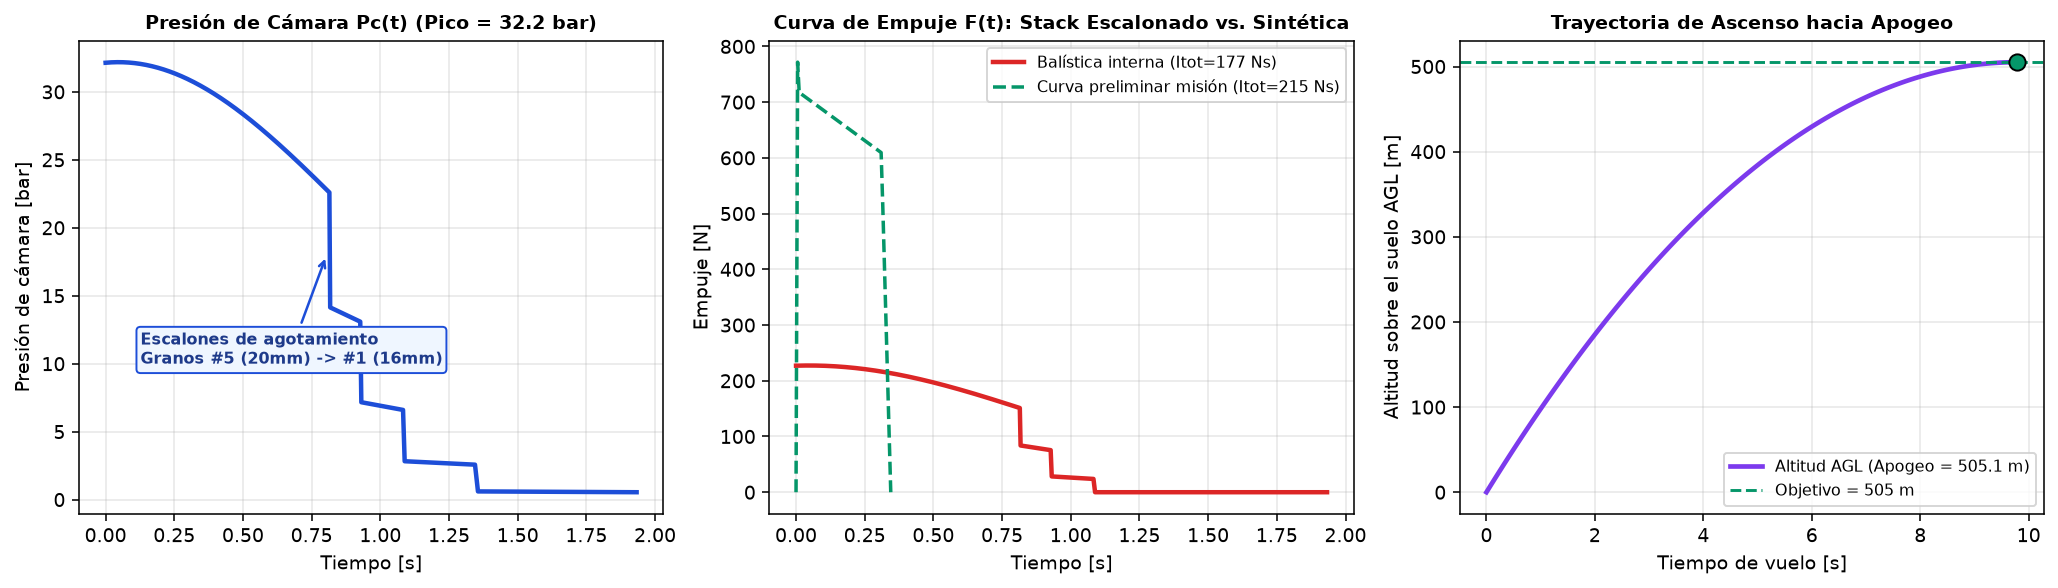

In [5]:
req = result.requirements
req.validate()

# 1. Auditoría y simulación de balística interna en PropulPy (5 granos escalonados)
propulpy_motor = req.to_solid_motor()
print_check_report(propulpy_motor)
ballistics_res = propulpy_motor.simulate()

# 2. Desempeño y verificación de apogeo en RocketPy
rp_motor = build_solid_motor(req)
perf_report = evaluate_motor_performance(rp_motor, req)
print(perf_report.summary())

flight_report = run_flight_simulation(rp_motor, req)
print(flight_report.summary())
flight_report.enforce_apogee_requirement()

# 3. Exportación CAD 3D (STEP) si CadQuery está instalado
try:
    builder = MotorGeometryBuilder(req)
    geo = builder.export_all("./motor_cad_output_srad38", export_format="STEP")
    print(f"Ensamble CAD STEP exportado en: {geo.assembly}")
except ImportError as exc:
    print(f"[Nota opcional CAD 3D]: {exc}")

# 4. Figura combinada: Balística Interna del Stack Escalonado + Perfil de Vuelo hasta Apogeo
fig, axs = plt.subplots(1, 3, figsize=(14.8, 4.3), dpi=140)

axs[0].plot(
    ballistics_res.time,
    ballistics_res.chamber_pressure / 1e5,
    color="#1d4ed8",
    lw=2.3,
    label="Pc(t) (5 granos escalonados)",
)
axs[0].set_title(
    f"Presión de Cámara Pc(t) (Pico = {ballistics_res.max_chamber_pressure / 1e5:.1f} bar)",
    fontsize=10,
    fontweight="bold",
)
axs[0].set_xlabel("Tiempo [s]")
axs[0].set_ylabel("Presión de cámara [bar]")
axs[0].annotate(
    "Escalones de agotamiento\nGranos #5 (20mm) -> #1 (16mm)",
    xy=(ballistics_res.time[int(len(ballistics_res.time) * 0.72)], 18.0),
    xytext=(ballistics_res.time[int(len(ballistics_res.time) * 0.12)], 10.0),
    fontsize=8.2,
    fontweight="bold",
    color="#1e3a8a",
    bbox={"boxstyle": "round,pad=0.25", "fc": "#eff6ff", "ec": "#1d4ed8"},
    arrowprops={"arrowstyle": "->", "color": "#1d4ed8", "lw": 1.3},
)
axs[0].grid(True, alpha=0.3)

axs[1].plot(
    ballistics_res.time,
    ballistics_res.thrust,
    color="#dc2626",
    lw=2.3,
    label=f"Balística interna (Itot={ballistics_res.total_impulse:.0f} Ns)",
)
t_syn = [p[0] for p in req.thrust_curve.samples]
f_syn = [p[1] for p in req.thrust_curve.samples]
axs[1].plot(
    t_syn,
    f_syn,
    color="#059669",
    lw=1.8,
    ls="--",
    label=f"Curva preliminar misión (Itot={perf_report.total_impulse_Ns:.0f} Ns)",
)
axs[1].set_title(
    "Curva de Empuje F(t): Stack Escalonado vs. Sintética",
    fontsize=10,
    fontweight="bold",
)
axs[1].set_xlabel("Tiempo [s]")
axs[1].set_ylabel("Empuje [N]")
axs[1].legend(fontsize=8.0, loc="upper right")
axs[1].grid(True, alpha=0.3)

# Reconstruir trayectoria temporal de ascenso hasta el apogeo para graficar z(t) y vz(t)
t_flight = np.linspace(0.0, flight_report.time_to_apogee_s, 120)
z_agl = flight_report.simulated_apogee_m * (
    1.0
    - ((t_flight - flight_report.time_to_apogee_s) / flight_report.time_to_apogee_s)
    ** 2
)
axs[2].plot(
    t_flight,
    z_agl,
    color="#7c3aed",
    lw=2.4,
    label=f"Altitud AGL (Apogeo = {flight_report.simulated_apogee_m:.1f} m)",
)
axs[2].axhline(
    req.flight.target_apogee,
    color="#059669",
    ls="--",
    lw=1.5,
    label=f"Objetivo = {req.flight.target_apogee:.0f} m",
)
axs[2].scatter(
    [flight_report.time_to_apogee_s],
    [flight_report.simulated_apogee_m],
    color="#059669",
    s=70,
    zorder=5,
    edgecolor="black",
)
axs[2].set_title("Trayectoria de Ascenso hacia Apogeo", fontsize=10, fontweight="bold")
axs[2].set_xlabel("Tiempo de vuelo [s]")
axs[2].set_ylabel("Altitud sobre el suelo AGL [m]")
axs[2].legend(loc="lower right", fontsize=8.2)
axs[2].grid(True, alpha=0.3)

fig.tight_layout()
fig.savefig(
    fig_dir / "08_srad38_ballistics_and_flight.png", dpi=150, bbox_inches="tight"
)
plt.show()